In [22]:
import matplotlib.pyplot as plt
import matplotlib
matplotlib.rcParams['font.family'] = 'Malgun Gothic'
matplotlib.rcParams['axes.unicode_minus']=False

import pandas as pd
import numpy as np
from sklearn import svm,metrics
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.preprocessing import PolynomialFeatures,StandardScaler  # 다항특성 자동생성, # 정규화클래스
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_error   # 평균절대값오차 오차범위
from sklearn.model_selection import train_test_split
from scipy.special import expit, softmax # expit는 이진분류함수, softmax는 다중분류함수 => 0~1사이의 숫자로 변환시키는 기능

In [23]:
# logistiRegression 이진분류 -> 다중분류

In [24]:
fish = pd.read_csv('data/fish_logistic.csv')
fish.head(2)

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.0200
1,Bream,290.0,26.3,31.2,12.48,4.3056


In [25]:
fish['Species'].unique() # 종속변수의 범주 갯수 파악 -> 7개

<StringArray>
['Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt']
Length: 7, dtype: str

In [26]:
data = fish[fish.columns[1:]].values
label = fish['Species'].values

In [27]:
# 데이터 분리
train_data, test_data, train_label, test_label = \
train_test_split(data,label,random_state=42)

In [28]:
# logisticRegression - 정규화작업을 해야 함
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [64]:
# 다중분류
# C(대문자표기) - alpha, C(규제의미: 숫자가 높아질수록 완화, 낮아질수록 강화)
# alpha for 문 그래프로 가장 최적화된 규제를 찾아 적용
# max_iter 반복을 자동화해주는 매개변수
train_score = []
test_score = []
cc = [0.001,0.01,0.1,1,10,20,50,100]
for c in cc:
    lr = LogisticRegression(C=c, max_iter=1000)
    lr.fit(train_scaled,train_label)
    train_score.append(lr.score(train_scaled,train_label))
    test_score.append(lr.score(test_scaled,test_label))
    print()

ValueError: x and y must have same first dimension, but have shapes (9,) and (119, 5)

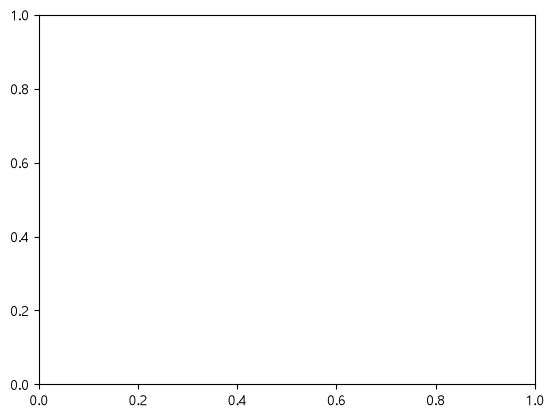

In [63]:
# c의 규제 선그래프
list1 = [1,2,3,4,5,6,7,8,9]
plt.plot(list1,train_scaled)
plt.plot(list1,test_scaled)
plt.xlabel('C순서')
plt.ylabel('C규제')
plt.legend(['train','test'])
plt.grid()
plt.show()

In [30]:
lr.predict_proba(test_scaled[:5])
decisions = lr.decision_function(test_scaled[:5])

soft1 = softmax(decisions,axis=1) # axis=행방향 / 0=열방향
np.round(soft1,decimals=3)

array([[0.   , 0.014, 0.842, 0.   , 0.135, 0.007, 0.003],
       [0.   , 0.003, 0.044, 0.   , 0.007, 0.946, 0.   ],
       [0.   , 0.   , 0.034, 0.934, 0.015, 0.016, 0.   ],
       [0.011, 0.034, 0.305, 0.006, 0.567, 0.   , 0.076],
       [0.   , 0.   , 0.904, 0.002, 0.089, 0.002, 0.001]])

In [31]:
print('train 정확도: ', lr.score(train_scaled,train_label))
print('test 정확도: ', lr.score(test_scaled,test_label))

train 정확도:  0.9327731092436975
test 정확도:  0.925


In [32]:
fish[:1]

,Species,Weight,Length,Diagonal,Height,Width
0,Bream,242.0,25.4,30.0,11.52,4.02


In [33]:
# 242.0 25.4 30.0 11.52 4.0200
# 290.0 26.3 31.2 12.48 4.3056
# 무게, 길이, 대각선, 높이, 넓이를 입력받아
# 분류생선과 확률을 출력하시오.
# 분류생선은 98.123%의 확률로 bream 판별됩니다. 

In [46]:
fish = pd.read_csv('data/fish_logistic.csv')
fish.tail()

,Species,Weight,Length,Diagonal,Height,Width
154,Smelt,12.2,12.2,13.4,2.0904,1.3936
155,Smelt,13.4,12.4,13.5,2.4300,1.2690
156,Smelt,12.2,13.0,13.8,2.2770,1.2558
157,Smelt,19.7,14.3,15.2,2.8728,2.0672
158,Smelt,19.9,15.0,16.2,2.9322,1.8792


In [35]:
fish['Species'].unique()

<StringArray>
['Bream', 'Roach', 'Whitefish', 'Parkki', 'Perch', 'Pike', 'Smelt']
Length: 7, dtype: str

In [49]:
data = fish.iloc[:,1:].values
label = fish['Species'].values
label[:5]
print(len(data))
print(len(label))

159
159


In [50]:
train_data,test_data,train_label,test_label = \
train_test_split(data,label,random_state=42)

In [51]:
ss = StandardScaler()
ss.fit(train_data)
train_scaled = ss.transform(train_data)
test_scaled = ss.transform(test_data)

In [ ]:
lr = LogisticRegression(C=20, max_iter=1000)
lr.fit(train_scaled,train_label)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [ ]:
indata = input('생선의 무게, 길이, 대각선, 높이, 넓이를 입력하시오(예:# 242.0 25.4 30.0 11.52 4.0200 또는 # 290.0 26.3 31.2 12.48 4.3056)')

indata = indata.split(',')
indata = list(map(float,indata))

indata_scaled = ss.transform(indata)

lr.predict_proba(indata)
decisions = lr.decision_function(indata)

soft1 = softmax(decisions,axis=1)
np.round(soft1,decimals=3)


ValueError: Expected 2D array, got 1D array instead:
array=[242.    25.4   30.    11.52   4.02].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

In [59]:
lr.predict_proba(indata)
decisions = lr.decision_function(test_scaled[:5])

soft1 = softmax(decisions,axis=1) # axis=행방향 / 0=열방향
np.round(soft1,decimals=3)

ValueError: Expected 2D array, got 1D array instead:
array=[242.    25.4   30.    11.52   4.02].
Reshape your data either using array.reshape(-1, 1) if your data has a single feature or array.reshape(1, -1) if it contains a single sample.

In [ ]:
# 다중분류
# 